# Validate metamodel vs dynamic SnapWave

Compare spectral metamodel bulk stats (`hs`, `tp`, `dm`) against the dynamic
reference run (`SnapWave_CASES_Dynamic/Dynamic_Cases_198601.nc`).

Only **isobath** sites are compared. Station QC (SnapWave cases + spectral
reconstruction) runs inside `utils.metamodel` and is applied automatically
here via `validate_against_dynamic`.

In [1]:
from utils import metamodel as mm
from utils import validation as val

print(f"metamodel : {mm.spectral_output_path()}")
print(f"dynamic   : {val.dynamic_output_path()}")

metamodel : /home/tausiaj/GitHub-GeoOcean/HyGloW/NorthCarolina/outputs/spectral_metamodel.nc
dynamic   : /home/tausiaj/GitHub-GeoOcean/HyGloW/NorthCarolina/SnapWave_CASES_Dynamic/Dynamic_Cases_198601.nc


In [8]:
# Align on shared isobath sites and overlapping time steps.
time = "1986-01-15"

result = val.validate_against_dynamic(time=time)
meta, dynamic = result.metamodel, result.dynamic

print(f"{len(result.sites)} sites, {meta.sizes['time']} timesteps")
if result.excluded_sites:
    print(f"QC excluded: {result.excluded_sites}")

2026-06-17 12:07:22,405 - NorthCarolina.validation - INFO - Loading metamodel from /home/tausiaj/GitHub-GeoOcean/HyGloW/NorthCarolina/outputs/spectral_metamodel.nc
2026-06-17 12:07:22,413 - NorthCarolina.validation - INFO - Loading dynamic reference from /home/tausiaj/GitHub-GeoOcean/HyGloW/NorthCarolina/SnapWave_CASES_Dynamic/Dynamic_Cases_198601.nc
2026-06-17 12:07:22,433 - NorthCarolina.validation - INFO - Aligned 185 station(s), 24 time step(s) [1986-01-15 … 1986-01-15]
2026-06-17 12:07:22,445 - NorthCarolina.validation - INFO - Computed metrics (pooled grouping): 3 row(s)
2026-06-17 12:07:22,446 - NorthCarolina.validation - INFO - Hs: n=4440  RMSE=368.132  BIAS=40.607  R²=-0.012
2026-06-17 12:07:22,446 - NorthCarolina.validation - INFO - Tp: n=4440  RMSE=0.791  BIAS=-0.174  R²=0.143
2026-06-17 12:07:22,447 - NorthCarolina.validation - INFO - Dm: n=4440  RMSE=58.595  BIAS=1.296  R²=nan


185 stations, 24 timesteps


In [3]:
# Pooled metrics (all sites × time)
result.metrics

,group,variable,label,n,bias,rmse,si,r2
0,all,hs,Hs,4440,40.607170,368.132182,0.993542,-0.012312
1,all,tp,Tp,4440,-0.174102,0.790885,0.123698,0.142847
2,all,dm,Dm,4440,1.295904,58.595489,NaN,NaN


In [4]:
# Metrics broken down by isobath depth (5 m / 10 m / 15 m)
val.metrics_table(meta, dynamic, groupby="site_label")

2026-06-17 12:03:30,426 - NorthCarolina.validation - INFO - Computed metrics (station_label grouping): 9 row(s)


,group,variable,label,n,bias,rmse,si,r2
0,10m,hs,Hs,1392,85.095901,551.203788,0.987755,-0.024535
1,10m,tp,Tp,1392,-0.225717,0.824407,0.128086,0.137719
2,10m,dm,Dm,1392,-1.400710,58.383040,NaN,NaN
3,15m,hs,Hs,1872,0.087116,0.186868,0.131364,0.713813
4,15m,tp,Tp,1872,-0.130643,0.751192,0.117878,0.164201
5,15m,dm,Dm,1872,4.785392,61.242705,NaN,NaN
6,5m,hs,Hs,1176,52.448352,389.912410,0.990336,-0.018161
7,5m,tp,Tp,1176,-0.182186,0.811690,0.126969,0.111141
8,5m,dm,Dm,1176,-1.066882,54.386189,NaN,NaN


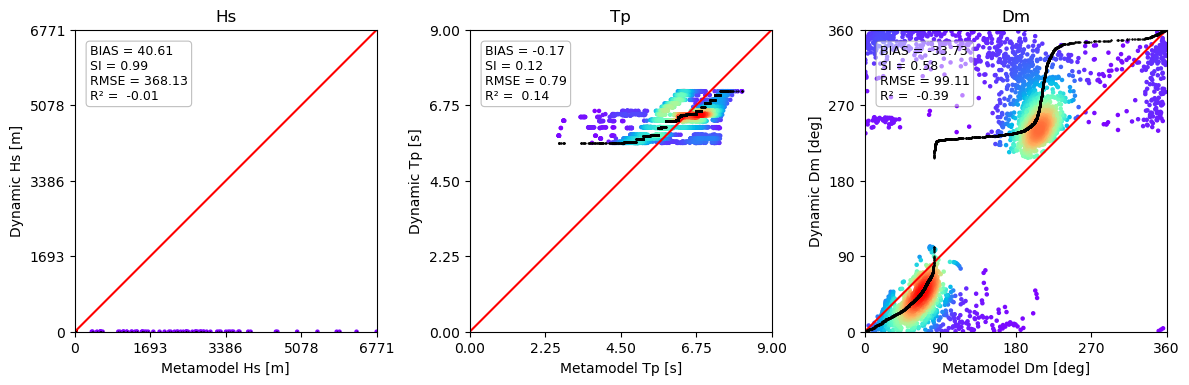

In [5]:
val.plot_scatter(meta, dynamic);

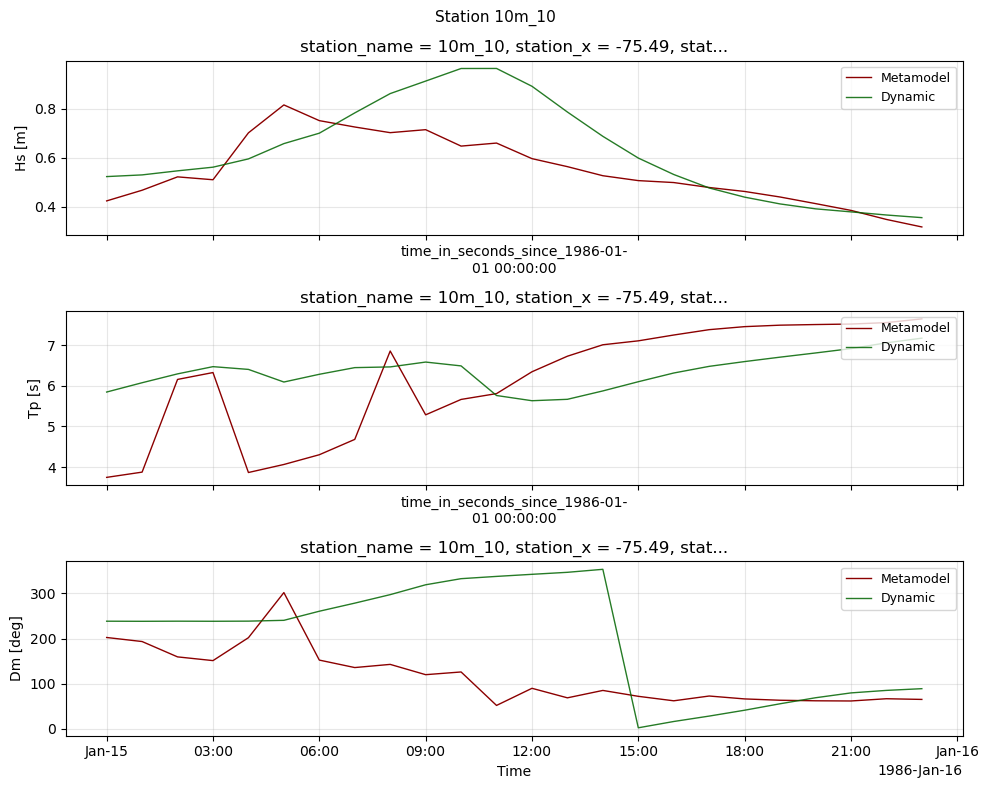

In [6]:
# Example time series at one isobath site
site = result.sites[0]
val.plot_timeseries(meta, dynamic, site);

2026-06-17 12:03:43,827 - NorthCarolina.validation - INFO - Computed metrics (station_label grouping): 9 row(s)
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Usi

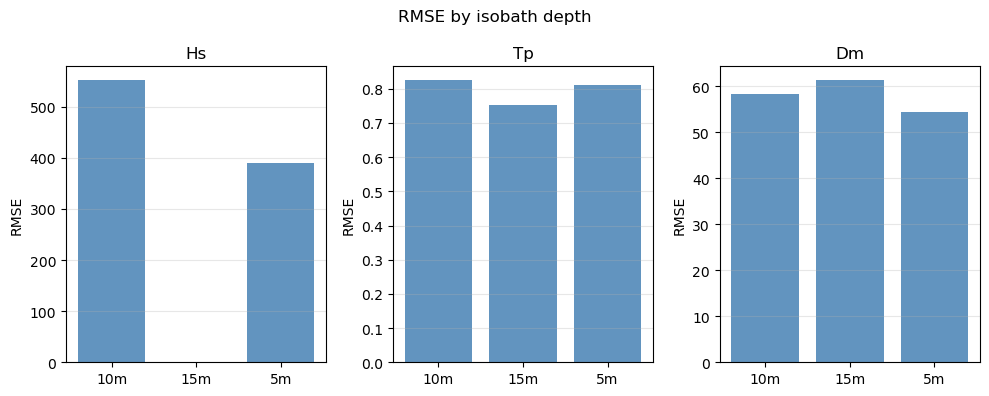

In [7]:
val.plot_metrics_by_depth(meta, dynamic, metric="rmse");